## Graficos Tesis

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("figures/tesis_phantom_ug")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
def rho_of_t(t, A, nu, alpha, rho0=1.0, t0=0.0):
    if alpha <= -1:
        raise ValueError("Se requiere alpha > -1 para que H sea real.")

    t = np.asarray(t, dtype=float)
    k = np.sqrt(3.0) * A / np.sqrt(1.0 + alpha)

    if np.isclose(nu, 0.5):
        return rho0 * np.exp(k * (t - t0))

    m = 0.5 - nu
    bracket = rho0**m + m * k * (t - t0)

    if np.any(bracket <= 0):
        return np.full_like(t, np.nan, dtype=float)

    return bracket**(1.0 / m)


def a_from_rho(rho, A, nu, alpha, rho0=1.0, a0=1.0):
    rho = np.asarray(rho, dtype=float)

    if np.isclose(nu, 1.0):
        exponent = (1.0 + alpha) / (3.0 * A) * np.log(rho / rho0)
    else:
        exponent = (1.0 + alpha) / (3.0 * A * (1.0 - nu)) * (
            rho**(1.0 - nu) - rho0**(1.0 - nu)
        )

    return a0 * np.exp(exponent)


def H_from_rho(rho, alpha):
    return np.sqrt((1.0 + alpha) * rho / 3.0)


def singular_time(A, nu, alpha, rho0=1.0, t0=0.0):
    if nu <= 0.5:
        return np.inf

    return t0 + (
        rho0**(0.5 - nu)
        * np.sqrt(1.0 + alpha)
        / (np.sqrt(3.0) * A * (nu - 0.5))
    )

In [3]:
def plot_interval_ug(
    nu_values,
    alpha_values,
    title,
    filename,
    A=1.0,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
    t_max=8.0,
    n_points=1200,
):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=False)

    linestyles = {
        alpha_values[0]: "-",
        alpha_values[1]: "--",
        alpha_values[2]: ":",
    }

    for nu in nu_values:
        for alpha in alpha_values:
            ts = singular_time(A, nu, alpha, rho0=rho0, t0=t0)

            if np.isfinite(ts):
                t_end = t0 + 0.97 * (ts - t0)
            else:
                t_end = t_max

            t = np.linspace(t0, t_end, n_points)

            rho = rho_of_t(t, A=A, nu=nu, alpha=alpha, rho0=rho0, t0=t0)
            a = a_from_rho(rho, A=A, nu=nu, alpha=alpha, rho0=rho0, a0=a0)
            H = H_from_rho(rho, alpha=alpha)

            label = rf"$\nu={nu:g}$, $\alpha={alpha:g}$"
            ls = linestyles[alpha]

            axes[0].plot(t, rho, linestyle=ls, linewidth=1.8, label=label)
            axes[1].plot(t, a, linestyle=ls, linewidth=1.8)
            axes[2].plot(t, H, linestyle=ls, linewidth=1.8)

    axes[0].set_ylabel(r"$\rho(t)$")
    axes[1].set_ylabel(r"$a(t)$")
    axes[2].set_ylabel(r"$H(t)$")

    axes[0].set_title(r"Densidad")
    axes[1].set_title(r"Factor de escala")
    axes[2].set_title(r"Parámetro de Hubble")

    for ax in axes:
        ax.set_xlabel(r"$t$")
        ax.set_yscale("log")
        ax.grid(True, which="both", alpha=0.3)

    axes[0].legend(fontsize=7, loc="best")

    fig.suptitle(title, y=1.03)
    plt.tight_layout()

    output_path = FIG_DIR / filename
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Figura guardada en: {output_path}")

In [11]:
def Hdot_from_rho(rho, A, nu):
    rho = np.asarray(rho, dtype=float)
    return 0.5 * A * rho**nu


def w_eff_from_rho(rho, A, nu, alpha):
    rho = np.asarray(rho, dtype=float)
    return -1.0 - (A / (1.0 + alpha)) * rho**(nu - 1.0)

In [12]:
def plot_hdot_weff_interval_ug(
    nu_values,
    alpha_values,
    title,
    filename,
    A=1.0,
    rho0=1.0,
    t0=0.0,
    t_max=8.0,
    n_points=1200,
):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    linestyles = {
        alpha_values[0]: "-",
        alpha_values[1]: "--",
        alpha_values[2]: ":",
    }

    for nu in nu_values:
        for alpha in alpha_values:
            ts = singular_time(A, nu, alpha, rho0=rho0, t0=t0)

            if np.isfinite(ts):
                t_end = t0 + 0.97 * (ts - t0)
            else:
                t_end = t_max

            t = np.linspace(t0, t_end, n_points)

            rho = rho_of_t(t, A=A, nu=nu, alpha=alpha, rho0=rho0, t0=t0)
            Hdot = Hdot_from_rho(rho, A=A, nu=nu)
            w_eff = w_eff_from_rho(rho, A=A, nu=nu, alpha=alpha)

            label = rf"$\nu={nu:g}$, $\alpha={alpha:g}$"
            ls = linestyles[alpha]

            axes[0].plot(t, Hdot, linestyle=ls, linewidth=1.8, label=label)
            axes[1].plot(t, w_eff, linestyle=ls, linewidth=1.8)

    axes[0].set_ylabel(r"$\dot H(t)$")
    axes[1].set_ylabel(r"$w_{\rm eff}(t)$")

    axes[0].set_xlabel(r"$t$")
    axes[1].set_xlabel(r"$t$")

    axes[0].set_yscale("log")
    axes[0].grid(True, which="both", alpha=0.3)
    axes[1].grid(True, alpha=0.3)

    axes[1].axhline(-1.0, color="black", linestyle="--", linewidth=1)

    axes[0].set_title(r"Derivada de Hubble")
    axes[1].set_title(r"Parámetro efectivo de estado")

    axes[0].legend(fontsize=7, loc="best")

    fig.suptitle(title, y=1.03)
    plt.tight_layout()

    output_path = FIG_DIR / filename
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Figura guardada en: {output_path}")

## Plots

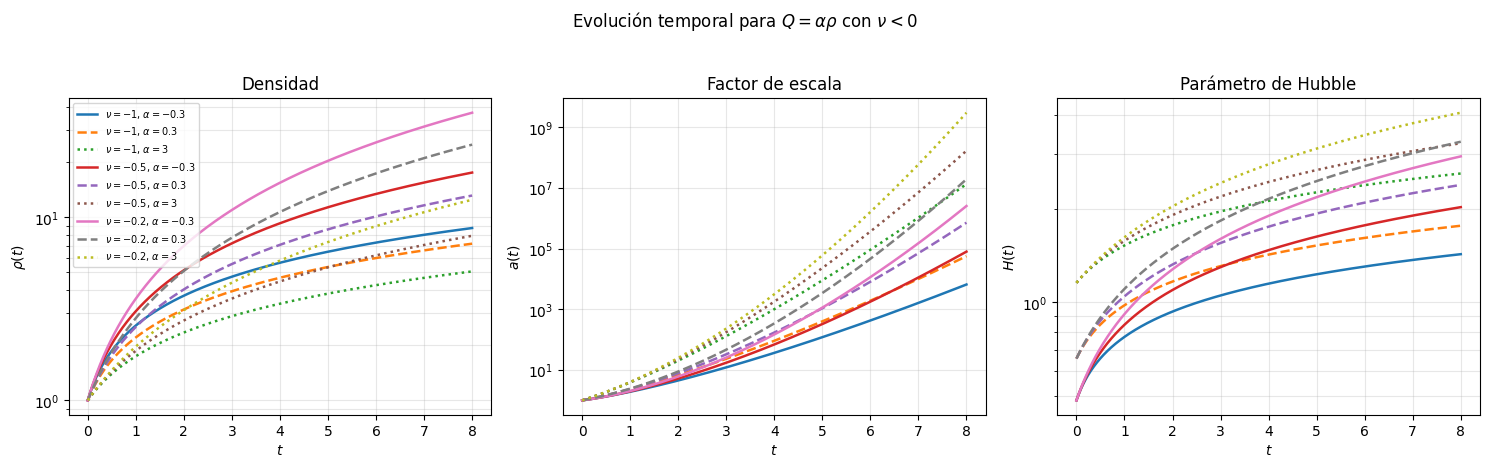

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_nu_menor_0.pdf


In [6]:
alpha_values = [-0.3, 0.3, 3.0]

plot_interval_ug(
    nu_values=[-1.0, -0.5, -0.2],
    alpha_values=alpha_values,
    title=r"Evolución temporal para $Q=\alpha\rho$ con $\nu<0$",
    filename="ug_intervalo_nu_menor_0.pdf",
    t_max=8.0,
)

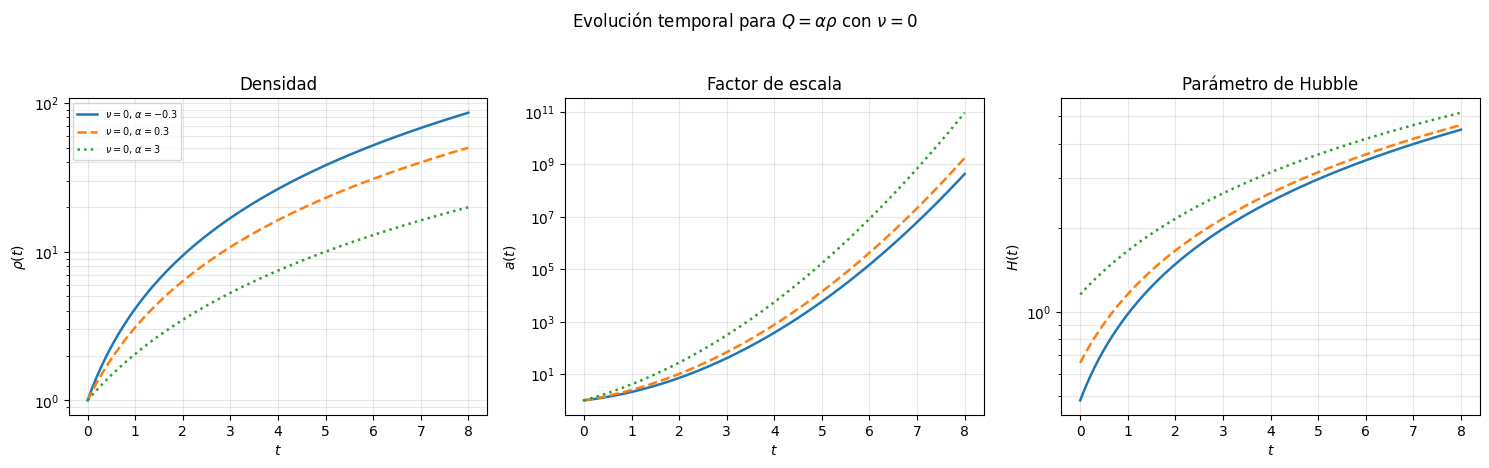

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_nu_igual_0.pdf


In [7]:
plot_interval_ug(
    nu_values=[0.0],
    alpha_values=alpha_values,
    title=r"Evolución temporal para $Q=\alpha\rho$ con $\nu=0$",
    filename="ug_intervalo_nu_igual_0.pdf",
    t_max=8.0,
)

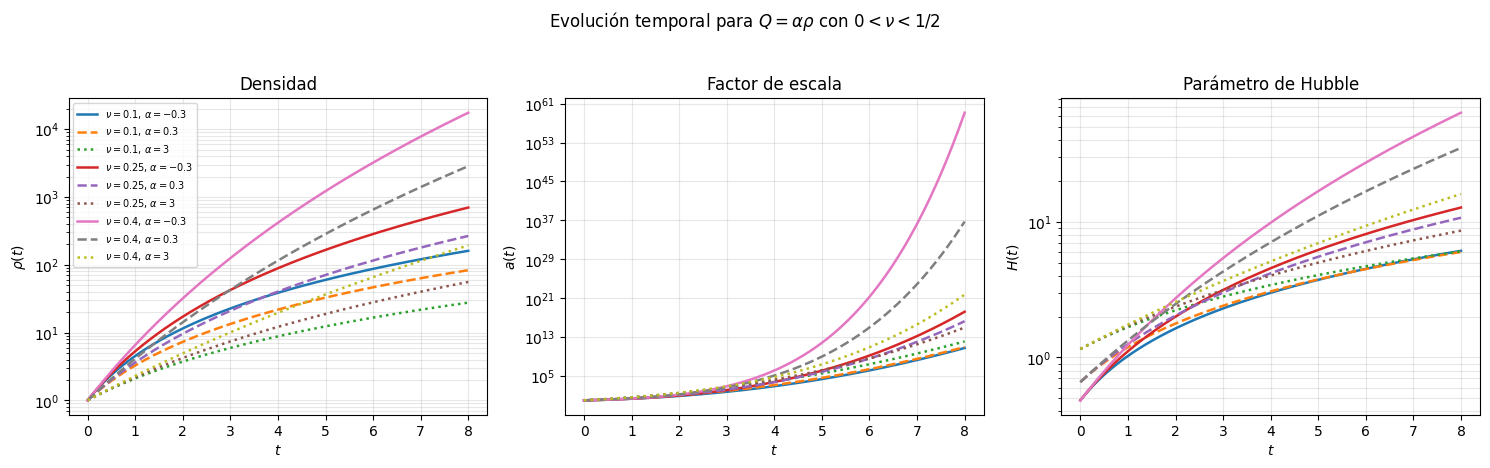

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_0_menor_nu_menor_1_2.pdf


In [8]:
plot_interval_ug(
    nu_values=[0.1, 0.25, 0.4],
    alpha_values=alpha_values,
    title=r"Evolución temporal para $Q=\alpha\rho$ con $0<\nu<1/2$",
    filename="ug_intervalo_0_menor_nu_menor_1_2.pdf",
    t_max=8.0,
)

/var/folders/7v/mpqjvkxx00lf3_k_1wpn9jsw0000gn/T/ipykernel_1882/556039439.py:30: RuntimeWarning: overflow encountered in exp
  return a0 * np.exp(exponent)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


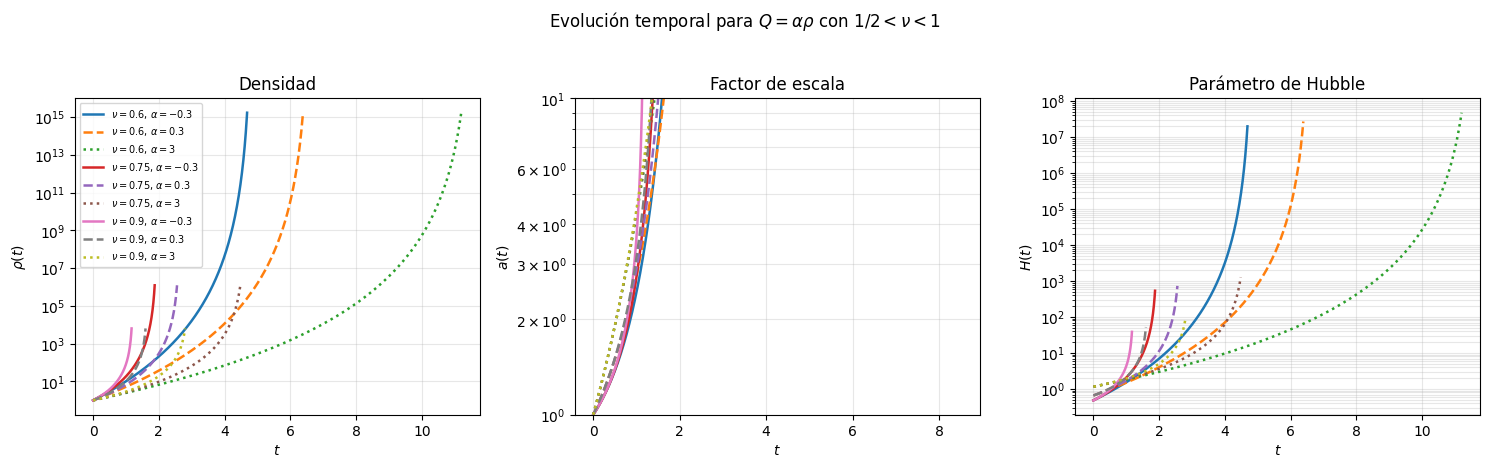

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_1_2_menor_nu_menor_1.pdf


In [9]:
plot_interval_ug(
    nu_values=[0.6, 0.75, 0.9],
    alpha_values=alpha_values,
    title=r"Evolución temporal para $Q=\alpha\rho$ con $1/2<\nu<1$",
    filename="ug_intervalo_1_2_menor_nu_menor_1.pdf",
    t_max=8.0,
)

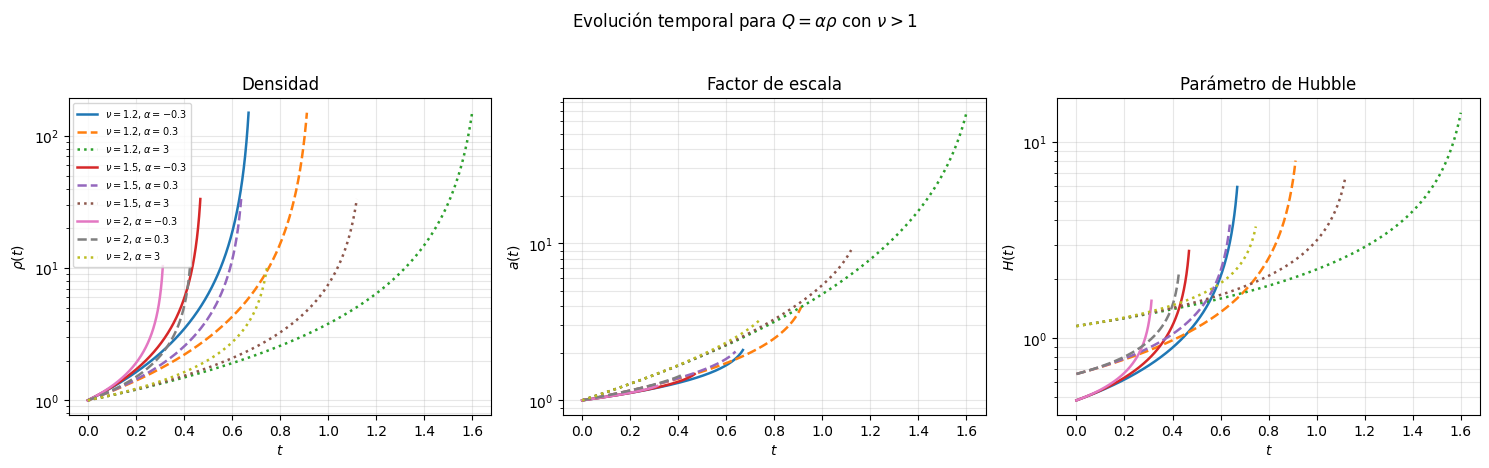

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_nu_mayor_1.pdf


In [10]:
plot_interval_ug(
    nu_values=[1.2, 1.5, 2.0],
    alpha_values=alpha_values,
    title=r"Evolución temporal para $Q=\alpha\rho$ con $\nu>1$",
    filename="ug_intervalo_nu_mayor_1.pdf",
    t_max=8.0,
)

## Panel con $\dot H$ y $\omega_{eff}$

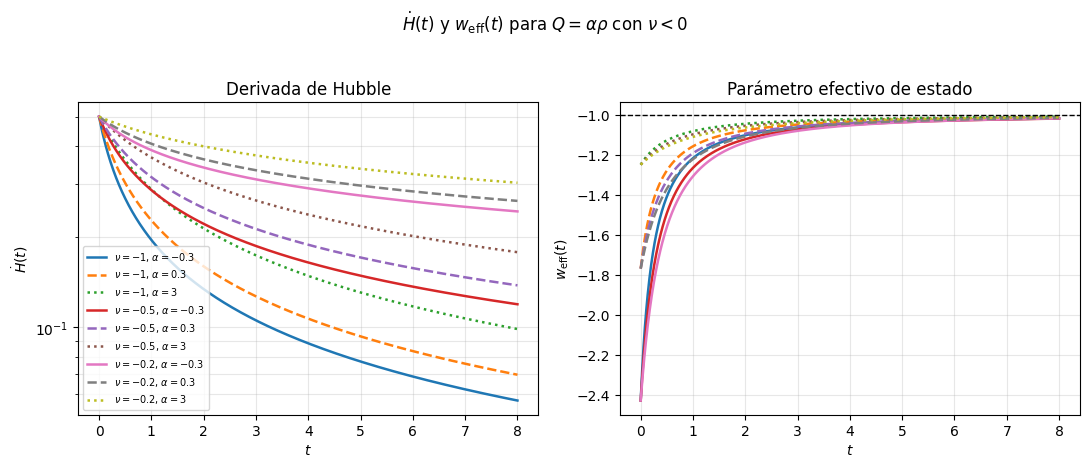

Figura guardada en: figures/tesis_phantom_ug/ug_hdot_weff_nu_menor_0.pdf


In [13]:
plot_hdot_weff_interval_ug(
    nu_values=[-1.0, -0.5, -0.2],
    alpha_values=alpha_values,
    title=r"$\dot H(t)$ y $w_{\rm eff}(t)$ para $Q=\alpha\rho$ con $\nu<0$",
    filename="ug_hdot_weff_nu_menor_0.pdf",
    t_max=8.0,
)

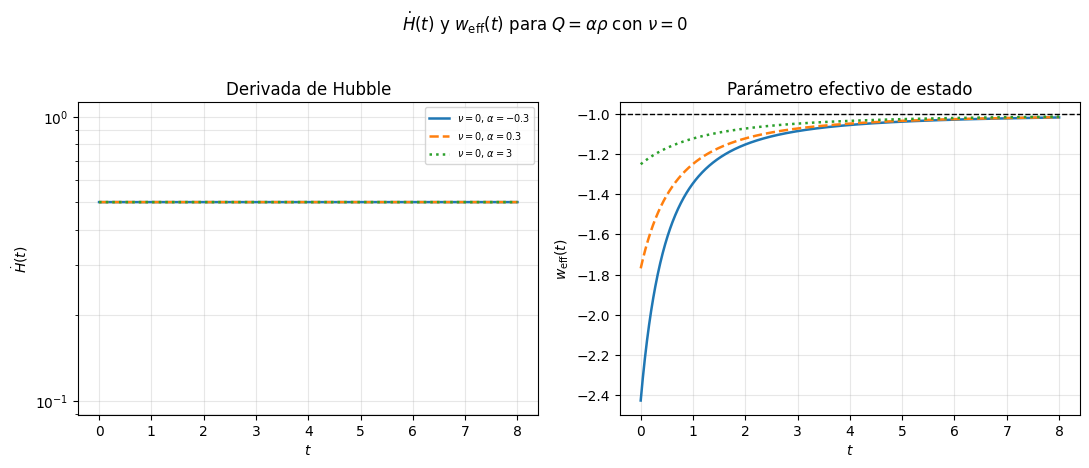

Figura guardada en: figures/tesis_phantom_ug/ug_hdot_weff_nu_igual_0.pdf


In [14]:
plot_hdot_weff_interval_ug(
    nu_values=[0.0],
    alpha_values=alpha_values,
    title=r"$\dot H(t)$ y $w_{\rm eff}(t)$ para $Q=\alpha\rho$ con $\nu=0$",
    filename="ug_hdot_weff_nu_igual_0.pdf",
    t_max=8.0,
)

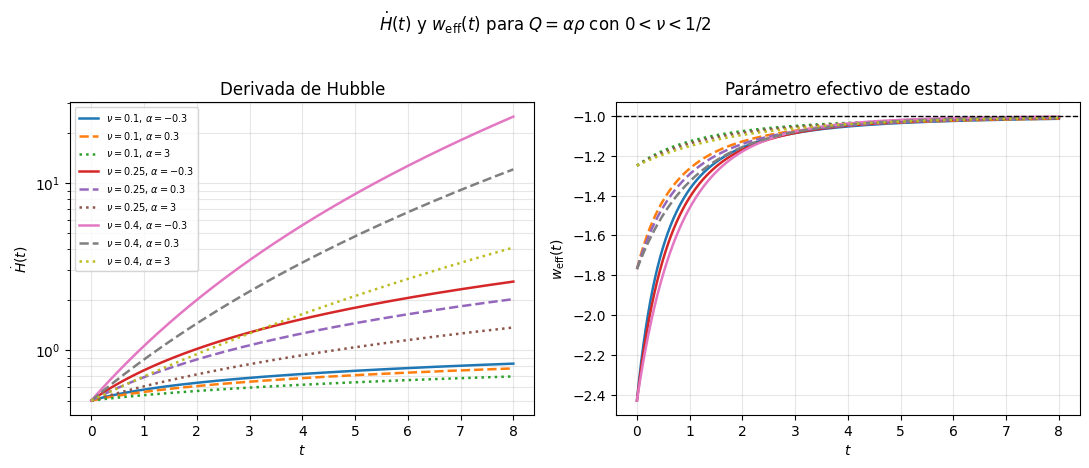

Figura guardada en: figures/tesis_phantom_ug/ug_hdot_weff_0_menor_nu_menor_1_2.pdf


In [15]:
plot_hdot_weff_interval_ug(
    nu_values=[0.1, 0.25, 0.4],
    alpha_values=alpha_values,
    title=r"$\dot H(t)$ y $w_{\rm eff}(t)$ para $Q=\alpha\rho$ con $0<\nu<1/2$",
    filename="ug_hdot_weff_0_menor_nu_menor_1_2.pdf",
    t_max=8.0,
)

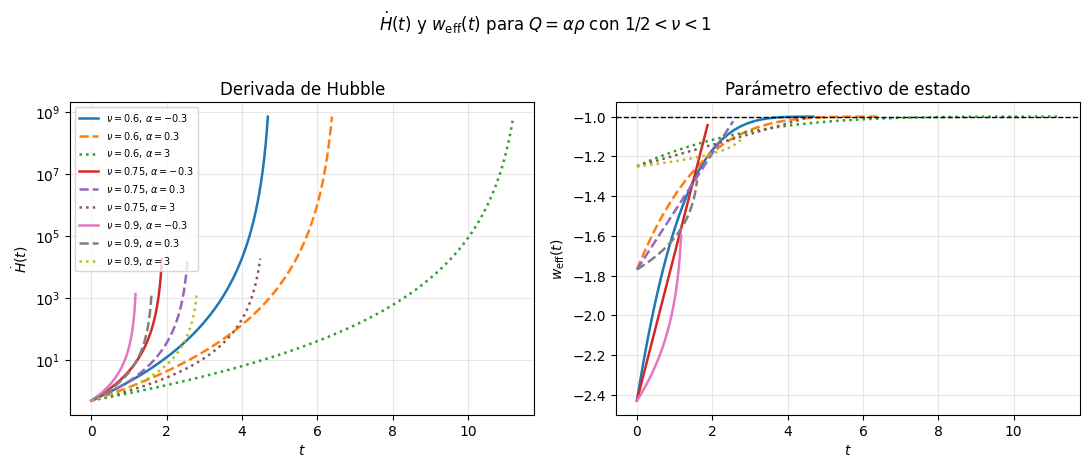

Figura guardada en: figures/tesis_phantom_ug/ug_hdot_weff_1_2_menor_nu_menor_1.pdf


In [16]:
plot_hdot_weff_interval_ug(
    nu_values=[0.6, 0.75, 0.9],
    alpha_values=alpha_values,
    title=r"$\dot H(t)$ y $w_{\rm eff}(t)$ para $Q=\alpha\rho$ con $1/2<\nu<1$",
    filename="ug_hdot_weff_1_2_menor_nu_menor_1.pdf",
    t_max=8.0,
)

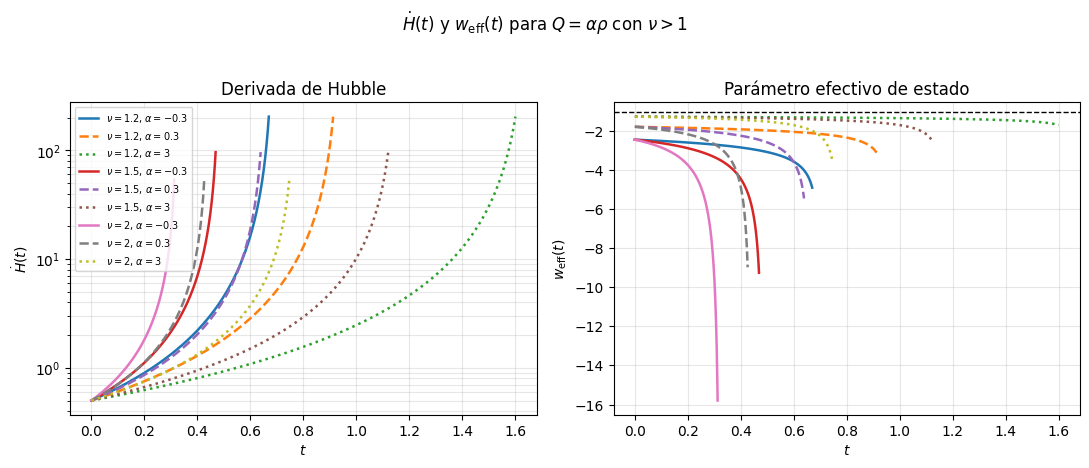

Figura guardada en: figures/tesis_phantom_ug/ug_hdot_weff_nu_mayor_1.pdf


In [17]:
plot_hdot_weff_interval_ug(
    nu_values=[1.2, 1.5, 2.0],
    alpha_values=alpha_values,
    title=r"$\dot H(t)$ y $w_{\rm eff}(t)$ para $Q=\alpha\rho$ con $\nu>1$",
    filename="ug_hdot_weff_nu_mayor_1.pdf",
    t_max=8.0,
)

## Gráfico del tiempo singular $t_s(\alpha)$

In [18]:
def plot_singular_time_vs_alpha(
    nu_values,
    alpha_min=-0.8,
    alpha_max=3.0,
    n_alpha=400,
    A=1.0,
    rho0=1.0,
    t0=0.0,
    filename="ug_tiempo_singular_vs_alpha.pdf",
):
    alpha_grid = np.linspace(alpha_min, alpha_max, n_alpha)

    plt.figure(figsize=(8, 5))

    for nu in nu_values:
        ts_values = [
            singular_time(A=A, nu=nu, alpha=alpha, rho0=rho0, t0=t0)
            for alpha in alpha_grid
        ]

        plt.plot(alpha_grid, ts_values, linewidth=2, label=rf"$\nu={nu:g}$")

    plt.xlabel(r"$\alpha$")
    plt.ylabel(r"$t_s$")
    plt.title(r"Dependencia del tiempo singular con $\alpha$")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    output_path = FIG_DIR / filename
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Figura guardada en: {output_path}")

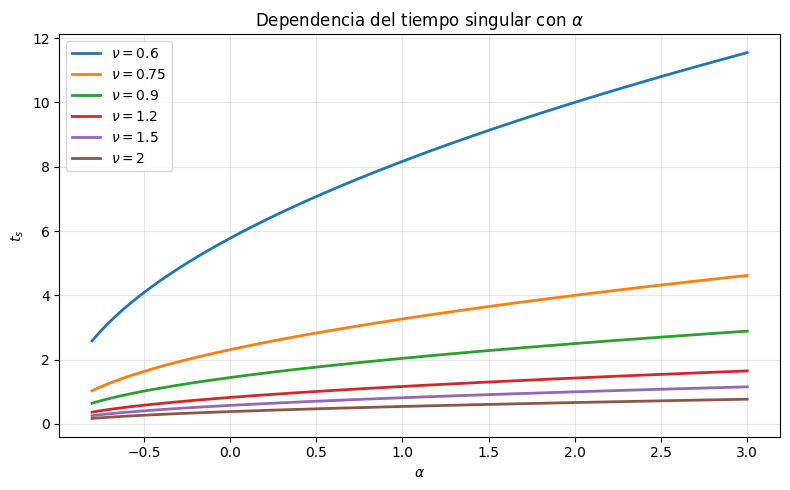

Figura guardada en: figures/tesis_phantom_ug/ug_tiempo_singular_vs_alpha.pdf


In [19]:
plot_singular_time_vs_alpha(
    nu_values=[0.6, 0.75, 0.9, 1.2, 1.5, 2.0],
    filename="ug_tiempo_singular_vs_alpha.pdf",
)